# Explicación difusa sencilla

**Grupo G7 · José · oct/2026**

Complemento del análisis de confianza (contrato técnico, sección 7): una frase corta en español que dice si tres presiones del ciclo están **bajas, medias o altas** y qué nivel del acumulador suele acompañar ese patrón. **Es una descripción de tendencias de los sensores, independiente del modelo; no es un clasificador ni explica cómo decide la MLP.** La clase la decide la MLP. Las reglas se construyeron a partir del EDA y de las etiquetas, no de la red, así que aquí también se **compara su pista con las predicciones fuera de pliegue de la MLP** para ver cuándo coinciden y cuándo se contradicen.

Las funciones están en `src/ic_g7/difuso.py` (solo numpy). Los límites de "baja/media/alta" se calculan **solo con entrenamiento** (percentiles 25, 50 y 75). El conjunto de prueba no se carga ni se consulta. Las etiquetas de entrenamiento se usan aquí únicamente para justificar el diseño y describir cómo se comporta la regla, no para ajustar ningún modelo.

In [1]:
import ast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPClassifier

from ic_g7 import config
from ic_g7.confianza import probabilidades_fuera_de_pliegue
from ic_g7.datos import cargar_entrenamiento
from ic_g7.difuso import (
    VARIABLES, activacion_reglas, ajustar_referencia, explicar, pertenencia,
)
from ic_g7.evaluacion import crear_cv
from ic_g7.pipeline import crear_pipeline

X, y, grupos = cargar_entrenamiento()
bar = {v: k for k, v in config.CLASE_POR_OBJETIVO.items()}
referencia = ajustar_referencia(X)
print(f"Entrenamiento: {len(X)} ciclos")
print("Variables:", VARIABLES)
display(pd.DataFrame(referencia, index=["p25", "p50", "p75"]).round(3))

Entrenamiento: 1827 ciclos
Variables: ('PS5_max', 'PS3_mean', 'PS1_mean')


,PS5_max,PS3_mean,PS1_mean
p25,8.666,1.733,158.110
p50,9.168,1.782,158.811
p75,9.892,1.931,160.914


**Predicciones de la MLP final.** Para comparar la pista con la red se usan las predicciones fuera de pliegue de la MLP+GA (semilla 42), con los mismos cinco pliegues por grupos: cada ciclo se predice con un modelo que no lo vio. No se reentrena ni se guarda ningún modelo.

In [2]:
fila_modelo = pd.read_csv(config.DIR_REPORTES / "resultados_jose.csv").set_index("modelo").loc[
    "MLP+GA (semilla 42)"]
modelo = crear_pipeline(MLPClassifier(**ast.literal_eval(fila_modelo["hiperparámetros"])))
pliegues = list(crear_cv().split(X, y, grupos))
P = probabilidades_fuera_de_pliegue(modelo, X, y, grupos, pliegues)
prediccion = P.argmax(axis=1)
print(f"Exactitud fuera de pliegue de la MLP: {(prediccion == y.to_numpy()).mean():.4f}")

Exactitud fuera de pliegue de la MLP: 0.8287


## 1. Por qué estas tres variables

El EDA (`01_eda.ipynb`, sección 4) evaluó cada estadístico de PS1–PS6 por separado con un árbol poco profundo y la validación por grupos, y propuso `PS5_max`, `PS3_mean` y `PS1_mean` (F1 macro individual ≈ 0,475, 0,352 y 0,302), descartando candidatas con |r| ≥ 0,95 respecto a una ya elegida. Aquí se comprueban dos cosas con los datos: que no son redundantes entre sí y cómo se distribuyen por clase.

,PS5_max,PS3_mean,PS1_mean
PS5_max,1.00,0.76,-0.07
PS3_mean,0.76,1.00,-0.68
PS1_mean,-0.07,-0.68,1.00


,PS5_max,PS3_mean,PS1_mean
bar,,,
90,9.234,1.805,160.400
100,9.226,1.754,159.200
115,9.191,1.769,160.338
130,8.748,1.738,157.526


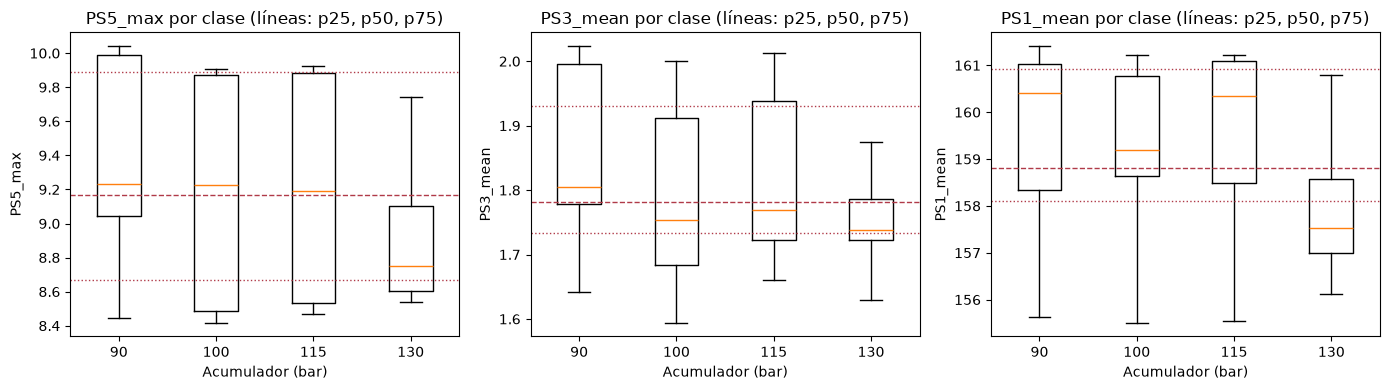

In [3]:
display(X[list(VARIABLES)].corr().round(2))
resumen = X[list(VARIABLES)].assign(bar=y.map(bar)).groupby("bar").median().round(3)
display(resumen)

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, v in zip(ejes, VARIABLES):
    ax.boxplot([X.loc[y == c, v] for c in sorted(bar)], tick_labels=[str(bar[c]) for c in sorted(bar)],
               showfliers=False)
    for p, estilo in zip(referencia[v], (":", "--", ":")):
        ax.axhline(p, color="#b03a48", linestyle=estilo, linewidth=1)
    ax.set(xlabel="Acumulador (bar)", ylabel=v, title=f"{v} por clase (líneas: p25, p50, p75)")
plt.tight_layout()
plt.show()

Las tres variables **no son redundantes** (|r| máximo 0,76). Se ve también lo importante: las tres separan la clase de **130 bar** (valores más bajos) del resto, pero **90, 100 y 115 bar se solapan casi por completo**. Por eso la explicación solo puede hablar de "presión óptima" frente a "por debajo de 130 bar", y no de distinguir entre 90, 100 y 115.

## 2. Funciones de pertenencia

Para cada variable: **baja** vale 1 hasta el percentil 25 y baja a 0 en la mediana; **alta** vale 0 hasta la mediana y sube a 1 en el percentil 75; **media** es lo que falta (triángulo con cima en la mediana). Los tres grados suman 1.

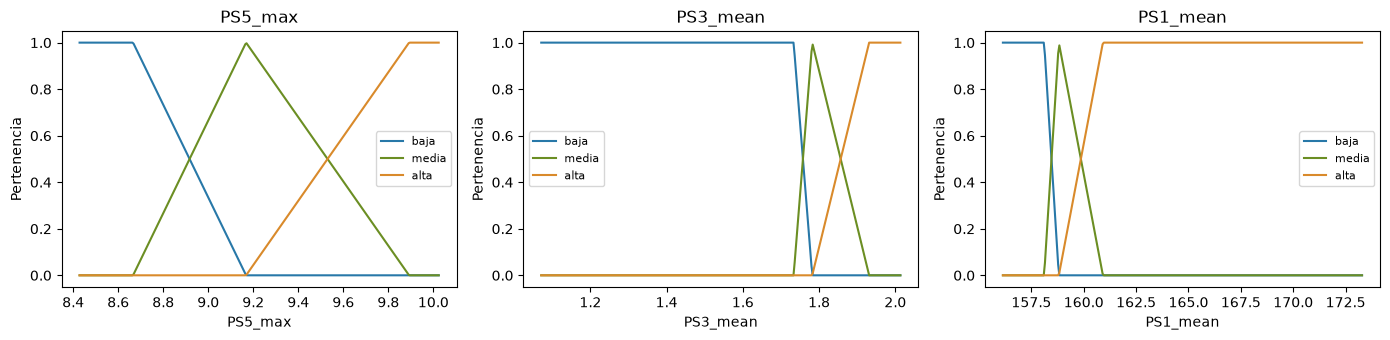

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, v in zip(ejes, VARIABLES):
    p25, p50, p75 = referencia[v]
    xs = np.linspace(X[v].quantile(0.01), X[v].quantile(0.99), 300)
    g = [pertenencia(x, referencia[v]) for x in xs]
    for etiqueta, color in zip(("baja", "media", "alta"), ("#2878a8", "#6b8e23", "#d98a2b")):
        ax.plot(xs, [d[etiqueta] for d in g], label=etiqueta, color=color)
    ax.set(xlabel=v, ylabel="Pertenencia", title=v)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Reglas y su comportamiento en entrenamiento

- **Regla "óptima"**: `PS5_max` baja **y** `PS3_mean` baja **y** `PS1_mean` baja (mínimo de los tres grados). Frase: apunta a presión óptima (130 bar).
- **Regla "menor"**: `PS5_max` alta **o** `PS3_mean` alta **o** `PS1_mean` alta (máximo). Frase: apunta a presión por debajo de 130 bar.
- Si ninguna llega a 0,5: valores intermedios o mezclados, sin nivel claro.

Las reglas se dejaron así por lectura del EDA y no se afinaron con ajustes sobre las etiquetas. Aquí se mide, sin ajustarlas, cómo se reparten las clases cuando cada regla está activa (grado ≥ 0,5).

In [5]:
activaciones = pd.DataFrame([activacion_reglas(X.iloc[i], referencia) for i in range(len(X))])
base = (y == 3).mean()
filas = []
for regla in ("optima", "menor"):
    activa = (activaciones[regla] >= 0.5).to_numpy()
    cuenta = y[activa].value_counts().reindex(sorted(bar), fill_value=0)
    fila = {"regla": regla, "ciclos activos": int(activa.sum()),
            "% de 130 bar entre los activos": round((y[activa] == 3).mean() * 100, 1),
            "% de 130 bar que la regla recoge": round(activa[(y == 3).to_numpy()].mean() * 100, 1)}
    fila.update({f"{bar[c]} bar": int(cuenta[c]) for c in sorted(bar)})
    filas.append(fila)
sin = ~((activaciones >= 0.5).any(axis=1)).to_numpy()
filas.append({"regla": "ninguna (sin nivel claro)", "ciclos activos": int(sin.sum()),
              "% de 130 bar entre los activos": round((y[sin] == 3).mean() * 100, 1),
              **{f"{bar[c]} bar": int((y[sin] == c).sum()) for c in sorted(bar)}})
display(pd.DataFrame(filas))
print(f"Para comparar: 130 bar es el {base:.1%} de todos los ciclos de entrenamiento.")

,regla,ciclos activos,% de 130 bar entre los activos,% de 130 bar que la regla recoge,90 bar,100 bar,115 bar,130 bar
0,optima,377,73.7,54.8,24,35,40,278
1,menor,766,9.7,14.6,359,149,184,74
2,ninguna (sin nivel claro),684,22.7,NaN,303,133,93,155


Para comparar: 130 bar es el 27.8% de todos los ciclos de entrenamiento.


Lectura de la tabla: cuando la regla **óptima** se activa, 7 de cada 10 ciclos son de 130 bar (frente al 28 % de base), pero solo recoge algo más de la mitad de los ciclos de 130 bar. Cuando se activa la regla **menor**, 9 de cada 10 ciclos son de menos de 130 bar, pero tampoco cubre a todos. La pista es útil como apoyo y no como veredicto.

## 4. ¿Coincide la pista con la MLP?

La tabla anterior compara las reglas con las **etiquetas reales**. Lo que ve el técnico en la app, en cambio, es la pista junto a la **predicción de la MLP**. Se cuentan los ciclos en que se contradicen: la regla "óptima" activa pero la MLP no predice 130 bar, o la regla "menor" activa pero la MLP predice 130 bar. Son discrepancias entre dos descripciones, no errores de la MLP (que puede tener razón); tampoco son una validación independiente ni una prueba de causa.

In [6]:
pred_optima = prediccion == 3
filas = []
for regla, activa, contradice in (
    ("optima", (activaciones["optima"] >= 0.5).to_numpy(), ~pred_optima),
    ("menor", (activaciones["menor"] >= 0.5).to_numpy(), pred_optima),
):
    filas.append({
        "regla": regla, "ciclos activos": int(activa.sum()),
        "discrepancias con la MLP": int((activa & contradice).sum()),
        "discrepancias (%)": round((activa & contradice).sum() / activa.sum() * 100, 1),
        "la MLP acierta en las discrepancias (%)": round(
            (prediccion == y.to_numpy())[activa & contradice].mean() * 100, 1),
    })
display(pd.DataFrame(filas))

,regla,ciclos activos,discrepancias con la MLP,discrepancias (%),la MLP acierta en las discrepancias (%)
0,optima,377,100,26.5,74.0
1,menor,766,33,4.3,63.6


## 5. Ejemplos

Un ciclo de entrenamiento por clase y la frase que devuelve `explicar`, usando la **predicción de la MLP** fuera de pliegue. Para no escoger a dedo, se toma el ciclo más cercano a la mediana de su clase (en las tres variables estandarizadas). Son casos típicos. Después se muestran dos casos donde la pista **sí contradice** a la MLP (el primero de cada regla, en el orden del archivo), para ver el aviso.

In [7]:
def mostrar(indice, titulo):
    fila = X.loc[indice]
    valores = ", ".join(f"{v}={fila[v]:.2f}" for v in VARIABLES)
    print(f"[{titulo}] real {bar[int(y[indice])]} bar, MLP {bar[int(prediccion[indice])]} bar · {valores}")
    print("   ->", explicar(fila, referencia, clase_predicha=int(prediccion[indice])))


Z = (X[list(VARIABLES)] - X[list(VARIABLES)].mean()) / X[list(VARIABLES)].std()
for clase in sorted(bar):
    z_clase = Z[(y == clase).to_numpy()]
    indice = (z_clase - z_clase.median()).abs().sum(axis=1).idxmin()
    mostrar(indice, f"típico de {bar[clase]} bar")
print()
optima_contradicha = np.flatnonzero((activaciones["optima"] >= 0.5).to_numpy() & ~pred_optima)
menor_contradicha = np.flatnonzero((activaciones["menor"] >= 0.5).to_numpy() & pred_optima)
mostrar(int(optima_contradicha[0]), "regla óptima contradicha")
mostrar(int(menor_contradicha[0]), "regla menor contradicha")

[típico de 90 bar] real 90 bar, MLP 90 bar · PS5_max=9.21, PS3_mean=1.81, PS1_mean=159.04
   -> PS5_max, PS3_mean y PS1_mean muestran valores intermedios o mezclados, así que no indican un nivel de presión claro.
[típico de 100 bar] real 100 bar, MLP 100 bar · PS5_max=9.23, PS3_mean=1.75, PS1_mean=158.85
   -> PS5_max, PS3_mean y PS1_mean muestran valores intermedios o mezclados, así que no indican un nivel de presión claro.
[típico de 115 bar] real 115 bar, MLP 115 bar · PS5_max=9.20, PS3_mean=1.77, PS1_mean=158.51
   -> PS5_max, PS3_mean y PS1_mean muestran valores intermedios o mezclados, así que no indican un nivel de presión claro.
[típico de 130 bar] real 130 bar, MLP 130 bar · PS5_max=8.75, PS3_mean=1.73, PS1_mean=157.54
   -> PS5_max, PS3_mean y PS1_mean están bajas, lo que apunta a una presión óptima (130 bar); en el entrenamiento, este patrón fue mucho más frecuente en ese nivel.

[regla óptima contradicha] real 130 bar, MLP 115 bar · PS5_max=8.81, PS3_mean=1.73, PS1_mean=157

## 6. Qué es y qué no es

- **Qué aporta**: una frase en lenguaje de planta para el técnico, con una regla que se puede explicar de memoria y que no requiere nada más que tres lecturas de presión. Describe tendencias de los sensores en el entrenamiento; **no explica cómo decide la MLP** (la red usa las 68 variables y no se inspecciona aquí).
- **Qué no hace**: no distingue 90, 100 y 115 bar, no reemplaza a la MLP y no prueba causalidad. Que `PS5_max`, `PS3_mean` y `PS1_mean` sean más bajas con 130 bar es una **asociación en un solo banco de pruebas**, donde cambian a la vez otros componentes; no se afirma que esa sea la causa física.
- **Cuánto coincide con la MLP** (sección 4): la regla "óptima" se activa en 377 ciclos y la MLP la contradice en 100 (26,5 %); la regla "menor" se activa en 766 y la contradice en 33 (4,3 %). En esos 133 casos la MLP no siempre se equivoca (acierta 74,0 % y 63,6 %), así que son avisos para revisar el ciclo, no veredictos.
- **Si la pista contradice a la MLP**, `explicar(fila, referencia, clase_predicha=...)` añade un aviso y la predicción del modelo no se toca.
- **Para la app**: `referencia_desde_entrenamiento()` calcula los percentiles con el entrenamiento (sin prueba); se llama una vez al arrancar y se pasa a `explicar` junto con la fila de 68 columnas.